In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from lib_pca.utils_sqrtm import sqrtm
from lib_pca.utils_plot import draw_cov
from lib_pca.lifted_pca import LiftedPCA
from lib_pca.uncertainty_aware_pca import UAPCA

[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


In [2]:
from sklearn import datasets
iris = datasets.load_iris()

In [3]:
X = iris.data

In [4]:
X.shape

(150, 4)

In [5]:
## PCA
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X)

In [6]:
X_reduced.shape

(150, 2)

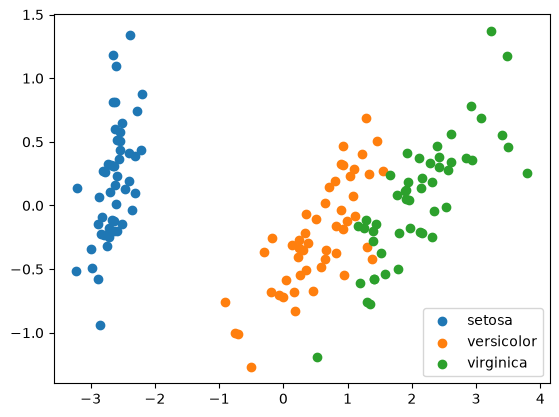

In [7]:
for k in range(3):
    plt.scatter(X_reduced[iris.target==k, 0], X_reduced[iris.target==k, 1], label=iris.target_names[k])

plt.legend()
plt.show()

In [8]:
for k in range(3):
    print((X[iris.target==k].shape))

(50, 4)
(50, 4)
(50, 4)


In [9]:
# Fix the support and optim over weights only
samples_iris = [torch.from_numpy(X[iris.target==k]) for k in range(3)]

lifted_pca = LiftedPCA(n_components=2, n_samples=500)
lifted_pca.fit(samples_iris, solver="fixed_weight")
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA(2)
pca_distributional.fit_from_samples(samples_iris)
eigenvectors_distributional = pca_distributional.components_# .numpy()

print("Barycenter cost:", lifted_pca.cost_barycenter(samples_iris))

INFO:2026-09-17 17:16:14,453:jax._src.xla_bridge:812: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
INFO: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory


Barycenter cost: tensor(1.3436)


In [10]:
lifted_pca.components_.shape

torch.Size([500, 4, 2])

In [11]:
pca_distributional.components_

tensor([[-0.3621,  0.6571],
        [ 0.0840,  0.7294],
        [-0.8565, -0.1741],
        [-0.3581, -0.0768]])

In [12]:
U_bary = lifted_pca.get_barycenter_components()

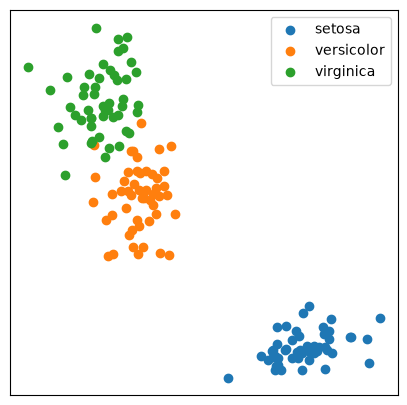

In [13]:
fig, ax = plt.subplots(
    nrows=1, 
    ncols=1,
    figsize=(5,5)
)

proj_points = torch.einsum("ij, ki -> kj", U_bary, torch.from_numpy(X)).numpy()
for k in range(3):
    ax.scatter(proj_points[iris.target == k, 0], proj_points[iris.target == k, 1], label=iris.target_names[k]) # , alpha=alpha[i*10+j])

ax.legend()

ax.set_xticks([])
ax.set_yticks([])

plt.show()

In [14]:
from lib_pca.utils_kde import projection_metric, kde_stiefel

In [15]:
lifted_pca.components_.shape

torch.Size([500, 4, 2])

In [16]:
Z = torch.randn(100, 4, 2)
U, _ = torch.linalg.qr(Z)

In [22]:
kde_stiefel(U, lifted_pca.components_, 0.25)

tensor([0.0105, 0.0134, 0.0172, 0.0090, 0.0120, 0.0137, 0.0168, 0.0156, 0.0145,
        0.0150, 0.0117, 0.0161, 0.0140, 0.0125, 0.0119, 0.0162, 0.0176, 0.0161,
        0.0082, 0.0139, 0.0204, 0.0151, 0.0157, 0.0170, 0.0163, 0.0119, 0.0133,
        0.0116, 0.0152, 0.0122, 0.0125, 0.0214, 0.0137, 0.0138, 0.0153, 0.0069,
        0.0111, 0.0166, 0.0151, 0.0061, 0.0123, 0.0178, 0.0167, 0.0102, 0.0087,
        0.0147, 0.0137, 0.0221, 0.0223, 0.0116, 0.0130, 0.0165, 0.0139, 0.0117,
        0.0153, 0.0194, 0.0097, 0.0143, 0.0177, 0.0167, 0.0166, 0.0189, 0.0121,
        0.0116, 0.0141, 0.0160, 0.0172, 0.0121, 0.0156, 0.0199, 0.0143, 0.0124,
        0.0164, 0.0139, 0.0141, 0.0120, 0.0183, 0.0189, 0.0152, 0.0134, 0.0204,
        0.0163, 0.0128, 0.0155, 0.0095, 0.0119, 0.0122, 0.0155, 0.0135, 0.0135,
        0.0154, 0.0167, 0.0172, 0.0100, 0.0141, 0.0125, 0.0159, 0.0134, 0.0245,
        0.0171])

In [26]:
print(kde_stiefel(lifted_pca.components_, lifted_pca.components_, 0.25).min(), kde_stiefel(lifted_pca.components_, lifted_pca.components_, 0.25).max())

tensor(0.0097) tensor(0.0274)


In [12]:
lifted_pca.components_.shape

torch.Size([500, 4, 2])

In [13]:
X.shape

(150, 4)

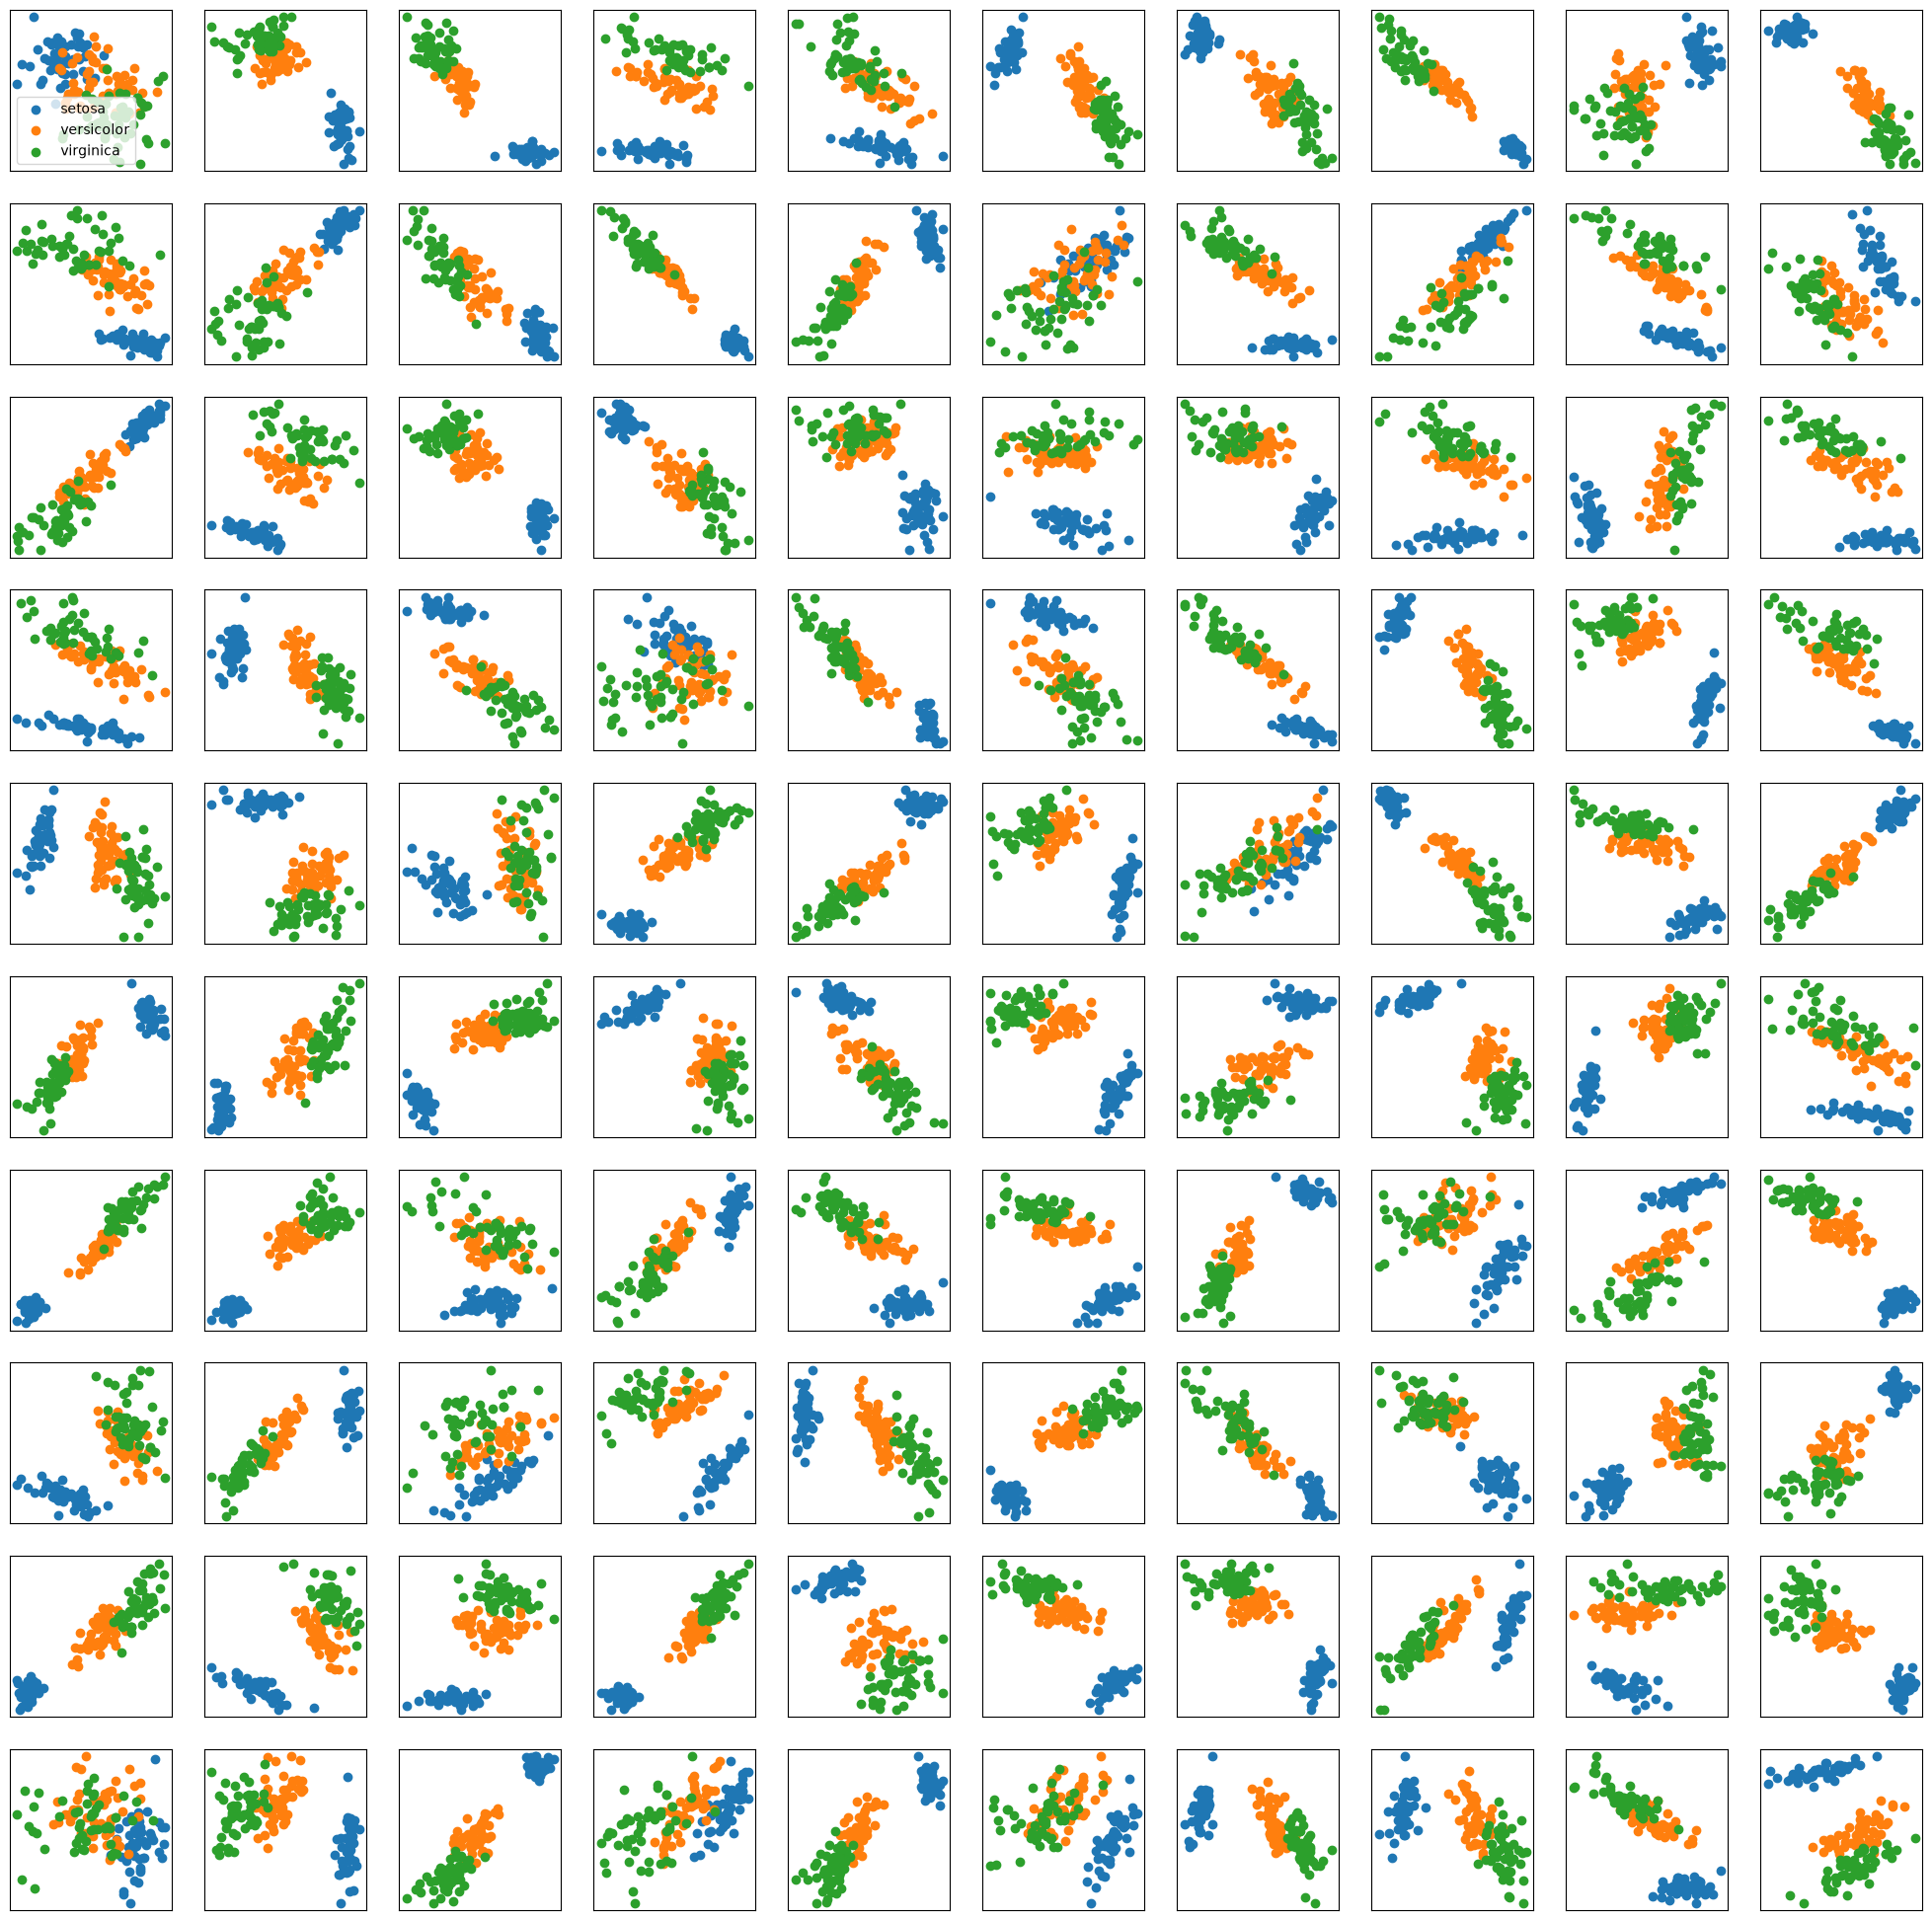

In [14]:
# weights = lifted_pca.weights_.numpy()
# min_weights = weights.min()
# max_weights = weights.max()
# diff = max_weights - min_weights
# alpha = 0.05 + 0.95 * (weights - min_weights) / diff

fig, axes = plt.subplots(
    nrows=10, 
    ncols=10,
    figsize=(25,25)
)

for i in range(10):
    for j in range(10):
        U = lifted_pca.components_[i*10+j]
        proj_points = torch.einsum("ij, ki -> kj", U, torch.from_numpy(X)).numpy()
        for k in range(3):
            axes[i, j].scatter(proj_points[iris.target == k, 0], proj_points[iris.target == k, 1], label=iris.target_names[k]) # , alpha=alpha[i*10+j])

        if i == 0 and j == 0:
            axes[i, j].legend()

        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])

plt.show()

In [15]:
lifted_pca.components_.shape

torch.Size([500, 4, 2])

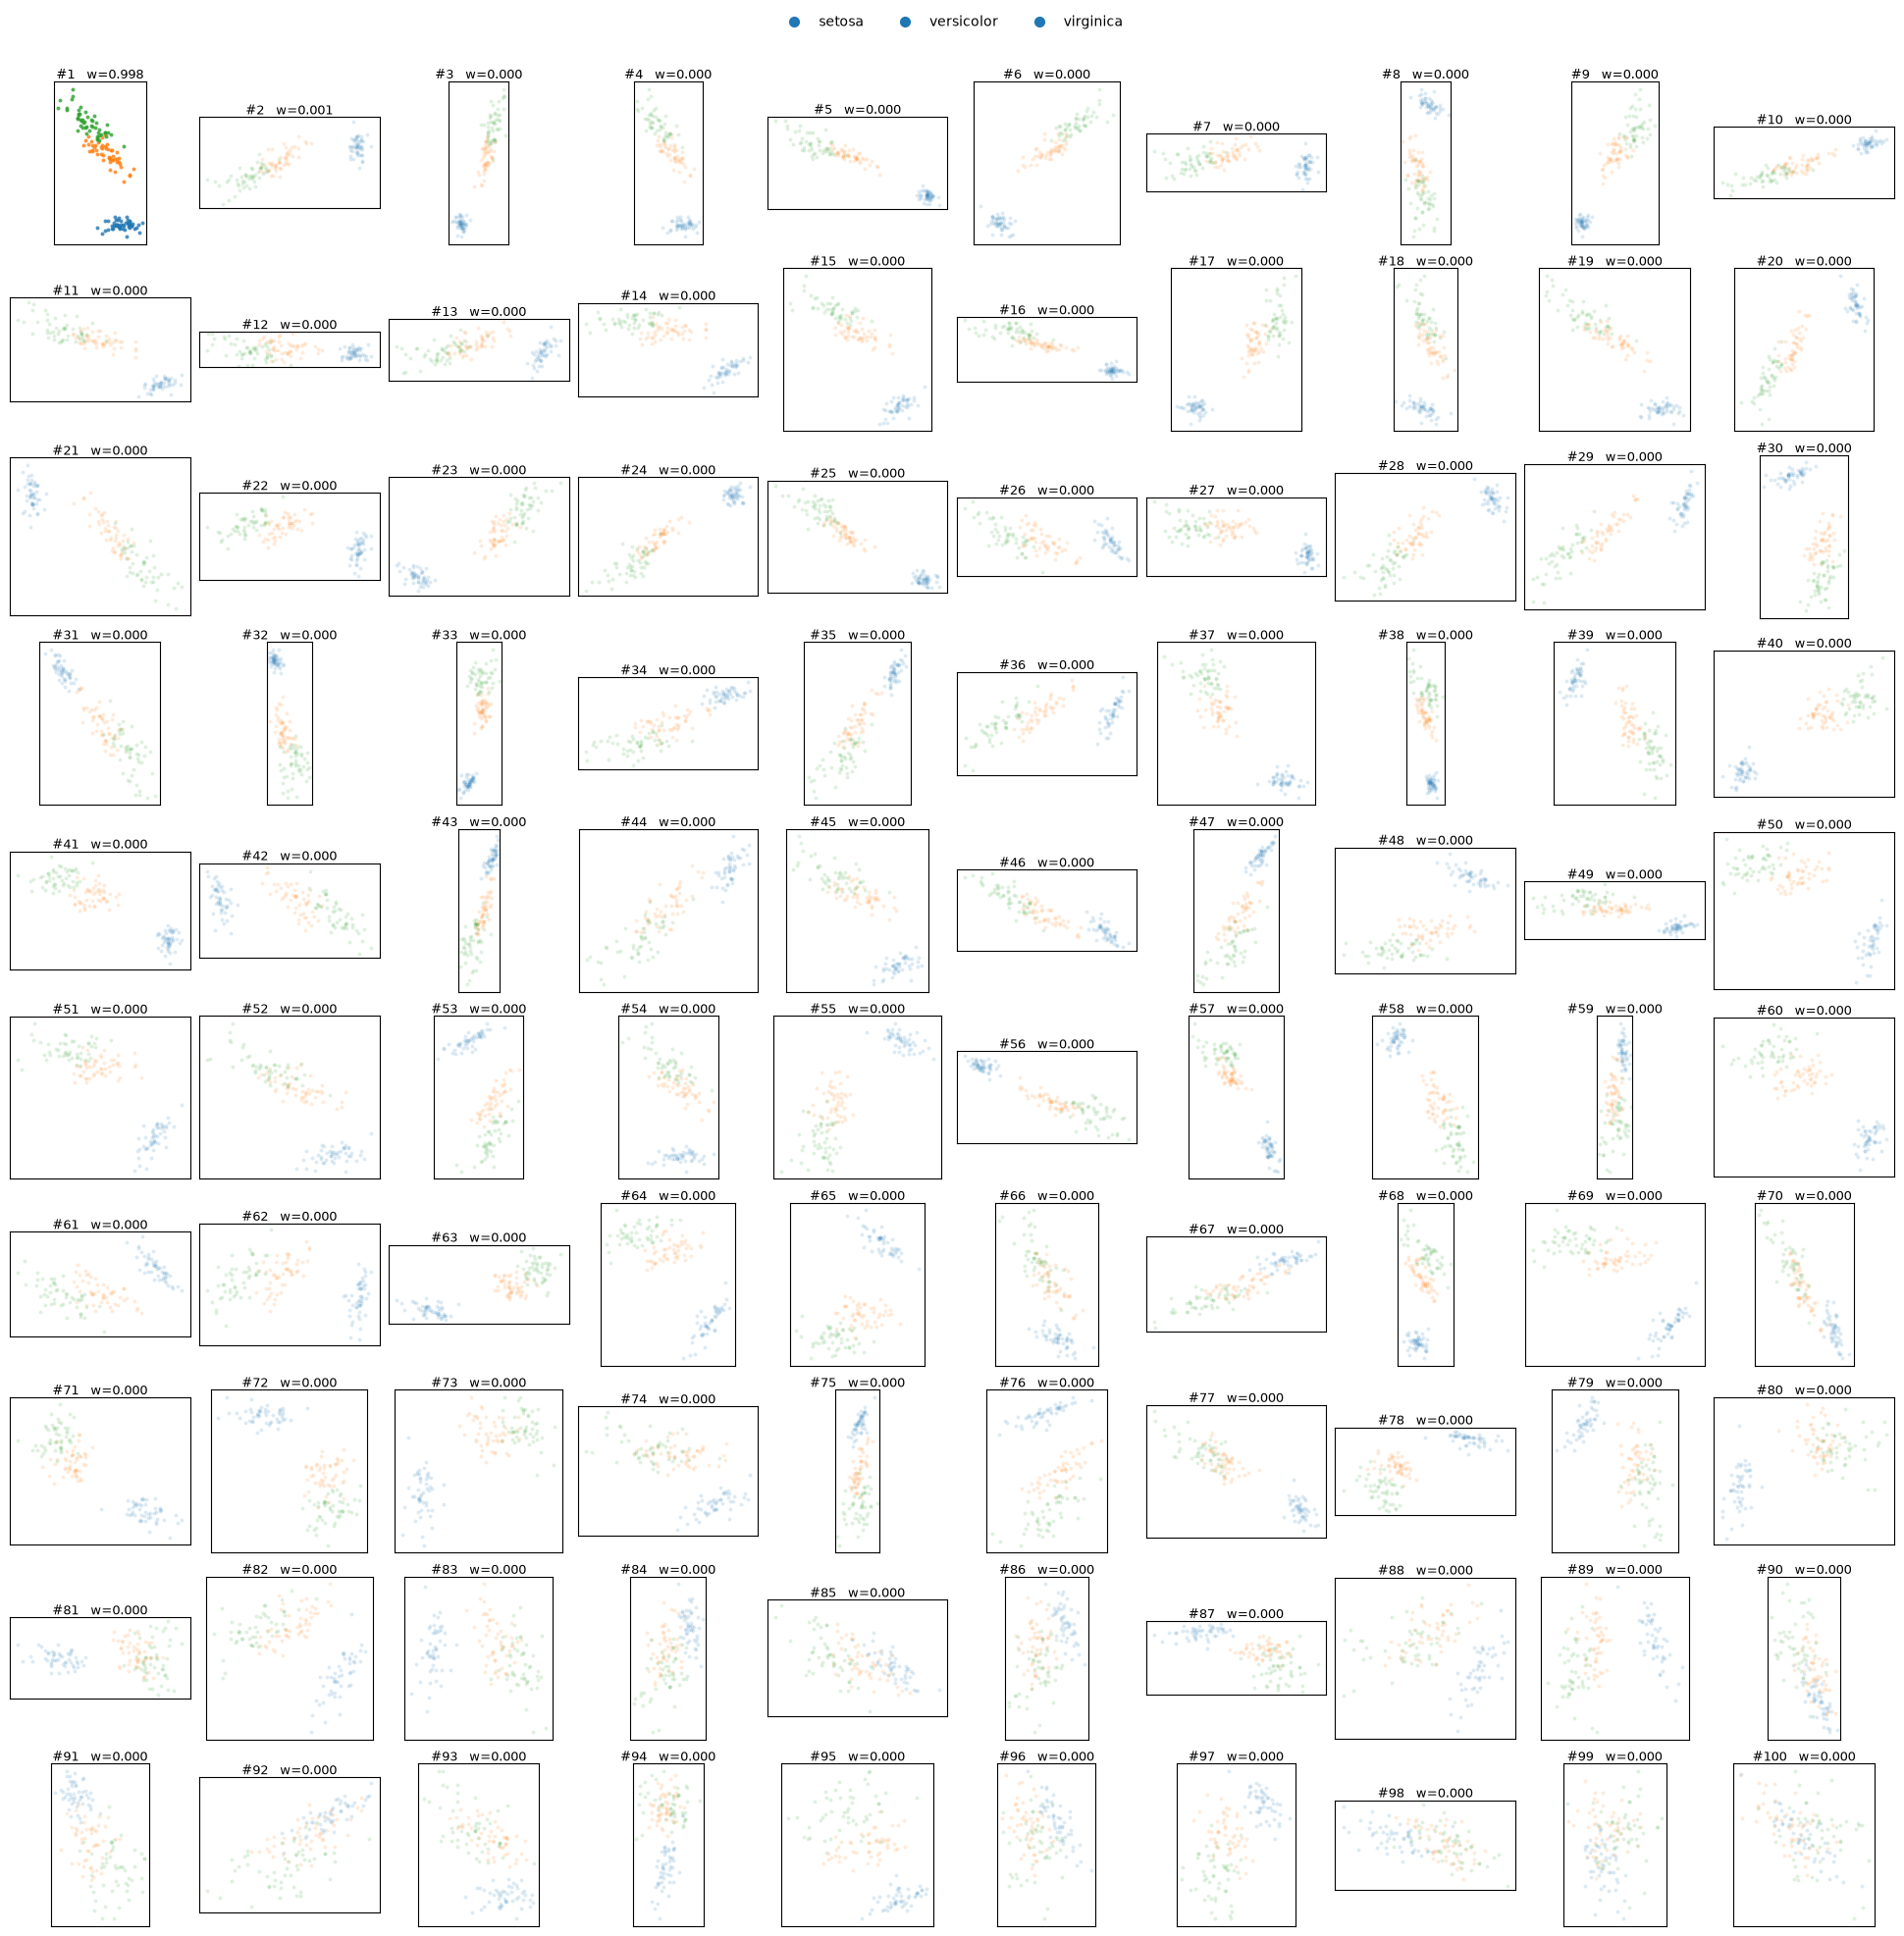

In [26]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------
weights = lifted_pca.weights_.detach().cpu().numpy()

# Sort planes by decreasing weight
order = np.argsort(weights)[::-1]

weights_sorted = weights[order]

# Robust normalization of weights
w = (weights_sorted - weights_sorted.min()) / (
    weights_sorted.max() - weights_sorted.min() + 1e-12
)

# Alpha for points: don't make low-weight planes completely disappear
point_alpha = 0.15 + 0.65 * w


# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------
fig, axes = plt.subplots(
    nrows=10,
    ncols=10,
    figsize=(20, 20),
)

X_torch = torch.from_numpy(X)

for plot_idx, plane_idx in enumerate(order):

    i, j = divmod(plot_idx, 10)

    ax = axes[i, j]

    # --------------------------------------------------------
    # Project data onto this 2D plane
    # U: (4, 2)
    # X: (N, 4)
    # --------------------------------------------------------
    U = lifted_pca.components_[plane_idx]

    if isinstance(U, torch.Tensor):
        U = U.detach().cpu()

    proj_points = X_torch @ U
    proj_points = proj_points.numpy()

    # --------------------------------------------------------
    # Plot the three classes
    # --------------------------------------------------------
    for k in range(3):
        mask = iris.target == k

        ax.scatter(
            proj_points[mask, 0],
            proj_points[mask, 1],
            s=8,
            alpha=point_alpha[plot_idx],
            linewidths=0,
            label=iris.target_names[k],
        )

    # --------------------------------------------------------
    # Plane information
    # --------------------------------------------------------
    ax.set_title(
        f"#{plot_idx + 1}   w={weights[plane_idx]:.3f}",
        fontsize=9,
        pad=2,
    )

    ax.set_xticks([])
    ax.set_yticks([])

    # Equal aspect ratio is important:
    # otherwise the geometry of the projected plane is distorted.
    ax.set_aspect("equal", adjustable="box")


# ------------------------------------------------------------
# One global legend
# ------------------------------------------------------------
handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markersize=7,
        label=iris.target_names[k],
    )
    for k in range(3)
]

fig.legend(
    handles=handles,
    loc="upper center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 1.0),
)

fig.subplots_adjust(
    left=0.02,
    right=0.98,
    bottom=0.02,
    top=0.96,
    wspace=0.05,
    hspace=0.15,
)

plt.show()

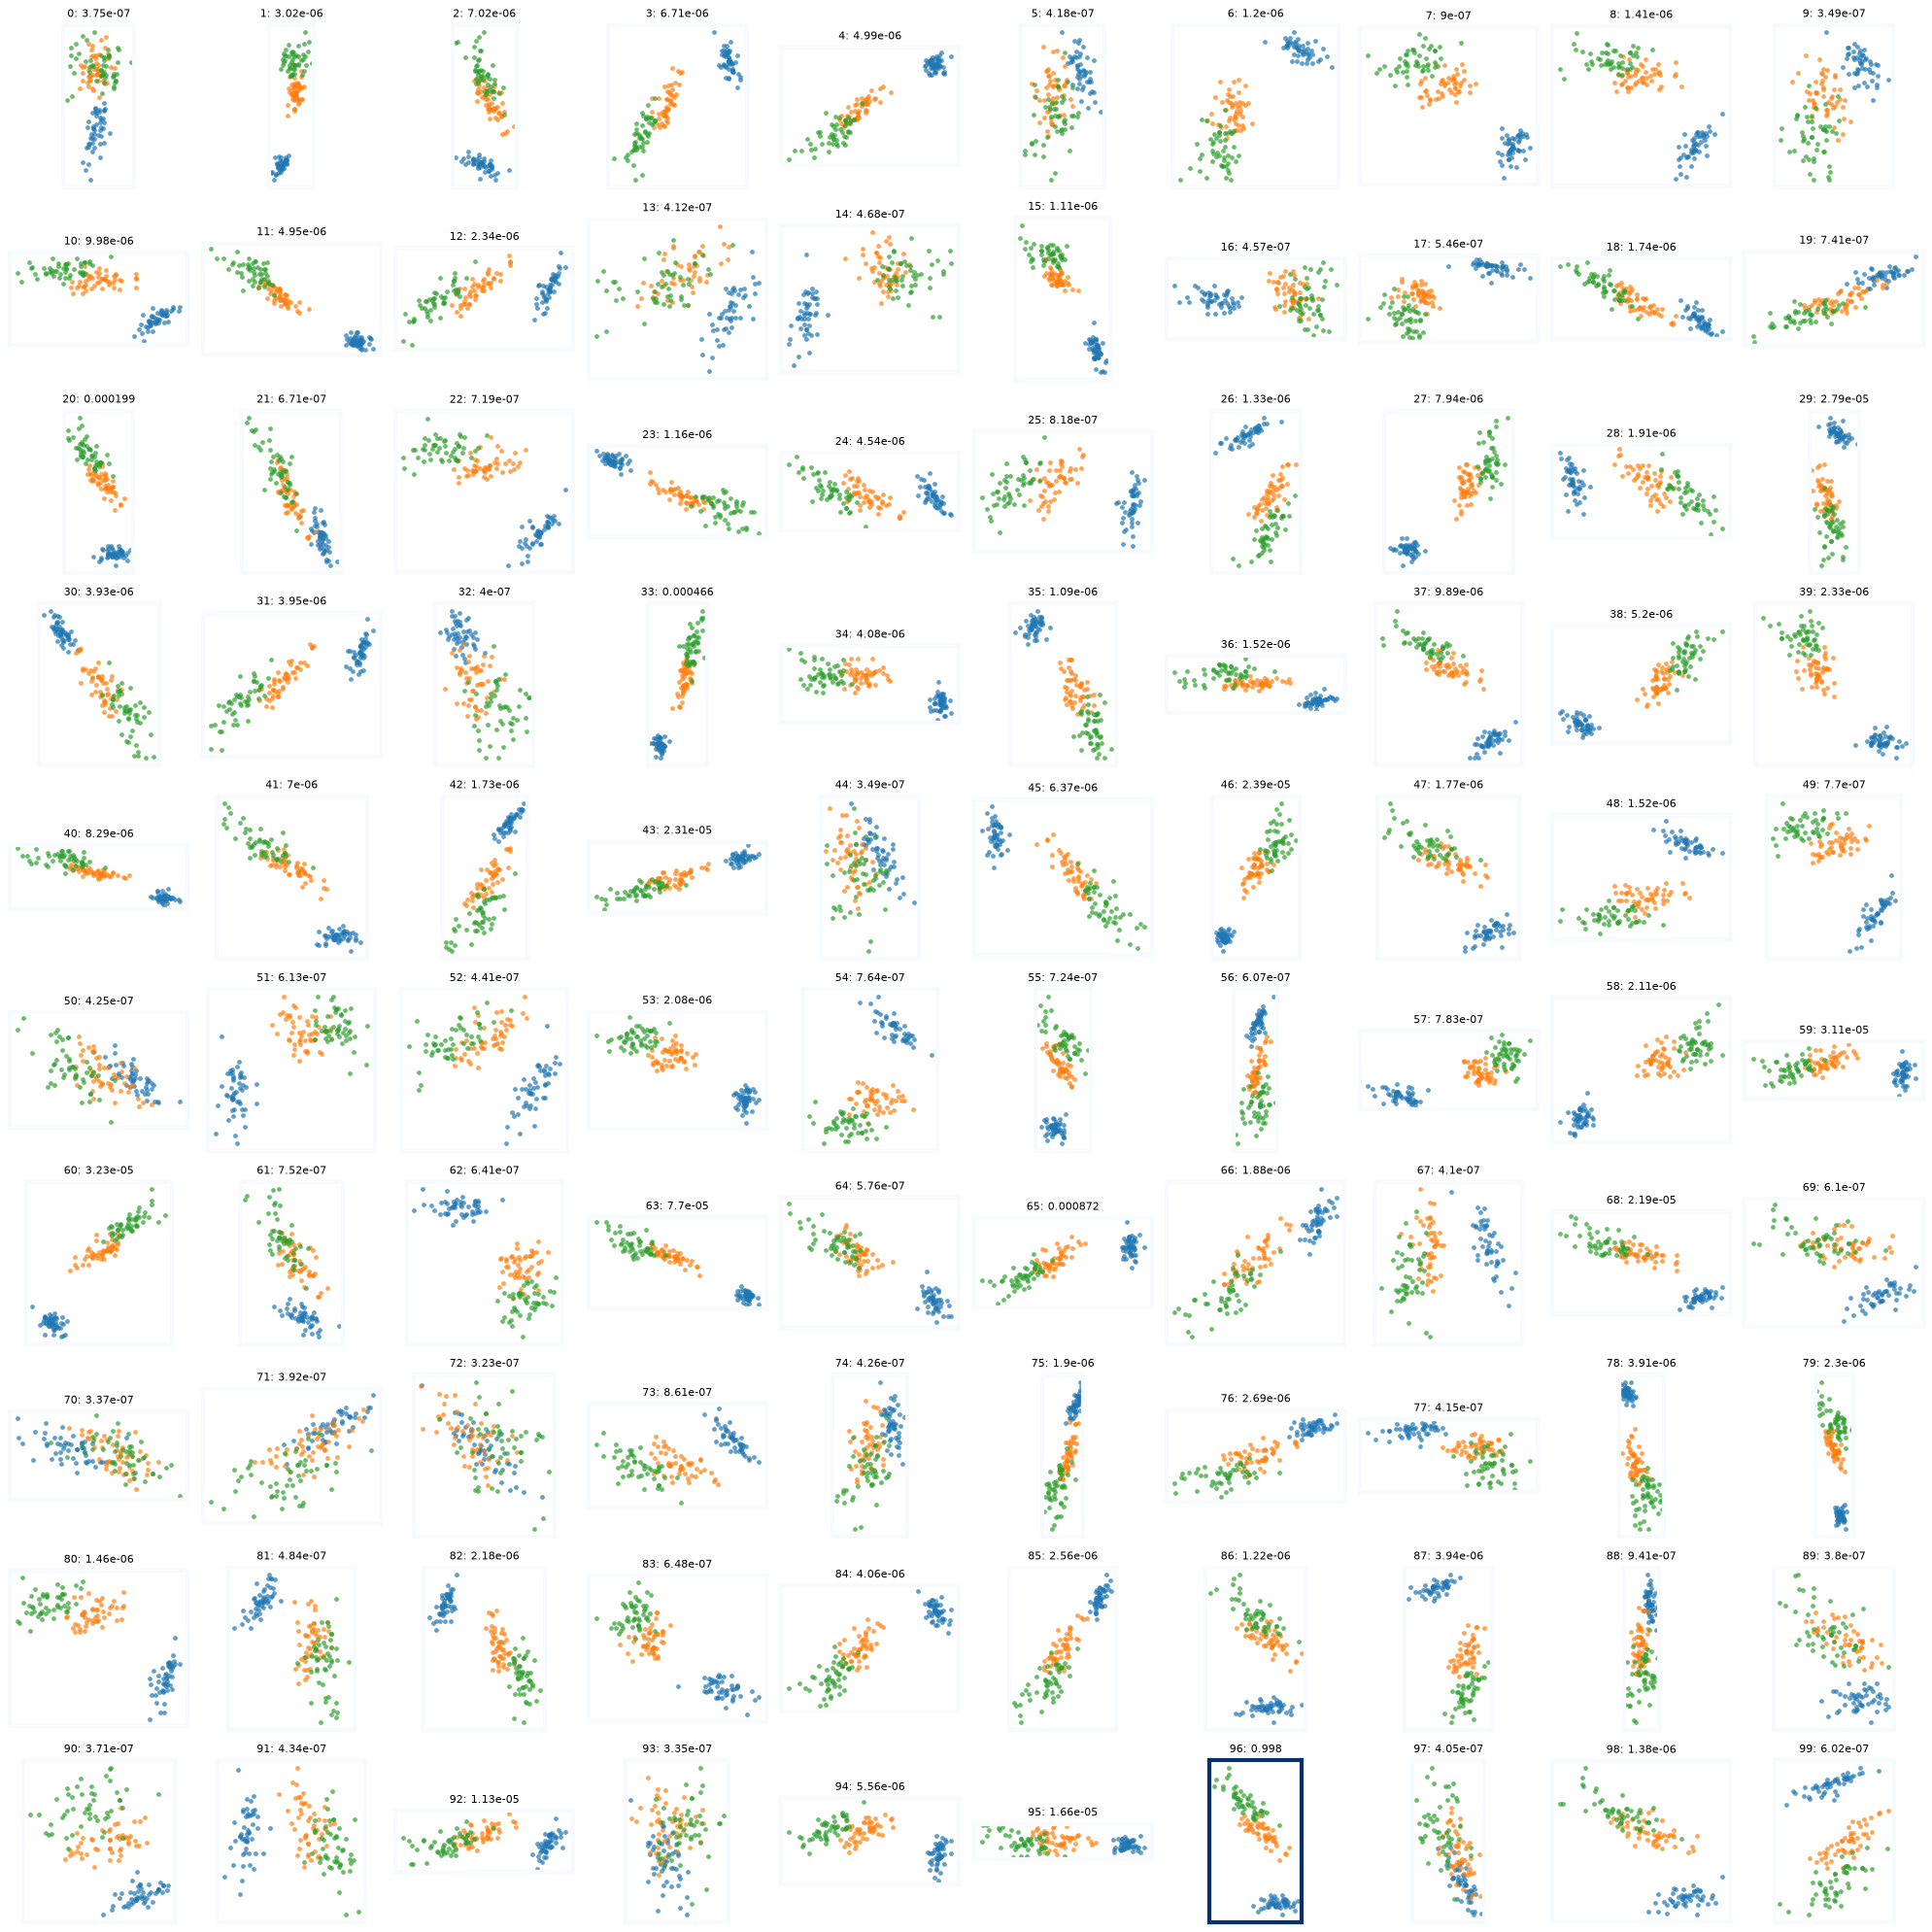

In [33]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib import colormaps

weights = lifted_pca.weights_.detach().cpu().numpy()

# Normalize weights
w = (weights - weights.min()) / (
    weights.max() - weights.min() + 1e-12
)

cmap = colormaps["Blues"]

fig, axes = plt.subplots(
    10, 10,
    figsize=(20, 20),
)

for idx, ax in enumerate(axes.flat):

    # Your original plane
    U = lifted_pca.components_[idx]

    # Your original projection -- DO NOT CHANGE THIS
    proj_points = torch.einsum(
        "ij,ki->kj",
        U,
        torch.from_numpy(X)
    ).numpy()

    # Plot classes
    for k in range(3):
        mask = iris.target == k

        ax.scatter(
            proj_points[mask, 0],
            proj_points[mask, 1],
            s=12,
            alpha=0.7,
            linewidths=0,
        )

    # Weight represented by the border
    color = cmap(w[idx])

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(3)
        spine.set_color(color)

    ax.set_title(
        f"{idx}: {weights[idx]:.3g}",
        fontsize=8,
    )

    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [31]:
# Z = pca_distributional.components_
Z = lifted_pca.components_[np.argmax(lifted_pca.weights_)]

In [33]:
Z.T @ Z

tensor([[1.0000, 0.0000],
        [0.0000, 1.0000]], dtype=torch.float64)

In [36]:
lifted_pca.components_[np.argmax(lifted_pca.weights_)].shape

torch.Size([4, 2])

In [19]:
from lib_pca.stiefel_kde import StiefelGrassmannKDE

# KDE on the Grassmann quotient represented by the Stiefel components.
stiefel_kde = StiefelGrassmannKDE(bandwidth=0.25).fit(lifted_pca.components_)
density = stiefel_kde.score_samples(lifted_pca.components_)

print("Density shape:", density.shape)
print("Density range:", density.min().item(), density.max().item())

Density shape: torch.Size([500])
Density range: 0.006057850078205451 0.01719727474677588


In [20]:
lifted_pca.components_.shape

torch.Size([500, 4, 2])

In [21]:
stiefel_kde.score_samples(U)


tensor([0.0066, 0.0084, 0.0108, 0.0056, 0.0075, 0.0086, 0.0105, 0.0098, 0.0091,
        0.0094, 0.0073, 0.0101, 0.0088, 0.0078, 0.0075, 0.0101, 0.0111, 0.0101,
        0.0052, 0.0087, 0.0128, 0.0095, 0.0099, 0.0107, 0.0102, 0.0075, 0.0083,
        0.0073, 0.0095, 0.0076, 0.0078, 0.0134, 0.0086, 0.0087, 0.0096, 0.0043,
        0.0069, 0.0104, 0.0095, 0.0039, 0.0077, 0.0112, 0.0105, 0.0064, 0.0054,
        0.0092, 0.0086, 0.0138, 0.0140, 0.0073, 0.0081, 0.0104, 0.0087, 0.0073,
        0.0096, 0.0121, 0.0061, 0.0089, 0.0111, 0.0105, 0.0104, 0.0118, 0.0076,
        0.0073, 0.0088, 0.0100, 0.0108, 0.0076, 0.0098, 0.0125, 0.0090, 0.0077,
        0.0103, 0.0087, 0.0088, 0.0075, 0.0115, 0.0118, 0.0095, 0.0084, 0.0128,
        0.0102, 0.0080, 0.0097, 0.0059, 0.0075, 0.0077, 0.0097, 0.0084, 0.0084,
        0.0096, 0.0104, 0.0108, 0.0062, 0.0088, 0.0078, 0.0100, 0.0084, 0.0153,
        0.0107])